# 01 · Globalization: one coordinate frame for every runner

**Run order:** `01_globalization` → `02_acceleration_utility` → `03_top_speed_utility`. Each notebook runs on its own (kernel `anaconda3`) and writes no files.

The Xsens suit records every trial in its own room axes. Before two runners can be compared, each trial is
turned into the same frame:

| axis | meaning |
|---|---|
| **+X** | the direction the runner travelled |
| **+Y** | the runner's left |
| **+Z** | up (gravity) |
| **origin** | the rear heel in the set position |

The question here: **can PCA find all three axes on its own?**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sprint_pipeline as SP          # loaders and the alignment every later notebook uses

RUNNER = "SB80"                       # the example runner for all three utility notebooks

## 1 · The raw recording

Exactly as the suit stored it: the runner can travel along any direction in the room, and the file starts
well before the set position (walking in, settling).

SB80: 868 frames at 60 Hz = 14.5 s, 64 landmarks


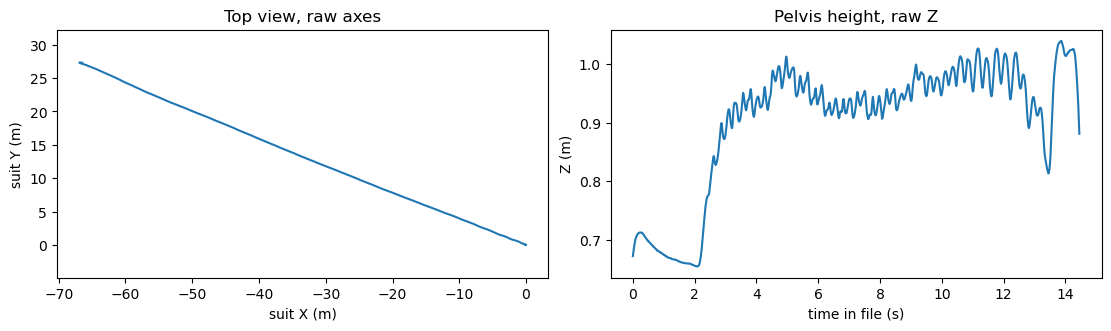

In [2]:
_, raw, fs = SP.load_c3d(SP.find(RUNNER))           # raw: (frames, 64 landmarks, x/y/z) in metres
print(f"{RUNNER}: {raw.shape[0]} frames at {fs} Hz = {raw.shape[0] / fs:.1f} s, {raw.shape[1]} landmarks")

pelvis = raw[:, SP.MK_PELVIS_ALL].mean(axis=1)       # 7 pelvis landmarks -> one point per frame
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
ax[0].plot(pelvis[:, 0], pelvis[:, 1])
ax[0].set(title="Top view, raw axes", xlabel="suit X (m)", ylabel="suit Y (m)")
ax[0].axis("equal")
ax[1].plot(np.arange(len(pelvis)) / fs, pelvis[:, 2])
ax[1].set(title="Pelvis height, raw Z", xlabel="time in file (s)", ylabel="Z (m)");

## 2 · PCA in three axes

Every landmark at every frame is one point in space. PCA finds the direction the cloud spreads most (PC1),
then the next (PC2), then the last (PC3). If PCA could do the whole job, PC1 would be forward and one of PC2/PC3
would point straight up.

"Straight up" is checked against **gravity**, which the suit measures directly (its Z axis comes from the
accelerometers). 0° = vertical, 90° = horizontal.

In [3]:
def pca_axes(raw):
    """3-axis PCA of the whole marker cloud: % variance and angle to gravity of PC1-PC3."""
    xyz = raw.reshape(-1, 3)
    _, s, axes = np.linalg.svd(xyz - xyz.mean(axis=0), full_matrices=False)
    to_gravity = np.degrees(np.arccos(np.abs(axes[:, 2])))
    return 100 * s ** 2 / (s ** 2).sum(), to_gravity

variance, to_gravity = pca_axes(raw)
pd.DataFrame({"variance_%": variance.round(3), "angle_to_gravity_deg": to_gravity.round(1)},
             index=["PC1", "PC2", "PC3"])

,variance_%,angle_to_gravity_deg
PC1,99.962,89.7
PC2,0.031,4.8
PC3,0.008,85.3


PC1 is the run itself: almost all of the spread, and horizontal. The vertical axis is whichever of PC2/PC3
sits closest to 0°. The same check for every runner (~20 s, reads all 30 files):

In [4]:
rows = []
for f in sorted(SP.C3D_DIR.glob("*.c3d")):
    rid = f.stem.split("-")[0].strip()
    if rid in SP.EXCLUDED_PIDS:                       # SB17: position tracking failed
        continue
    _, to_g = pca_axes(SP.load_c3d(f)[1])
    rows.append({"runner": rid, "PCA_up_axis": f"PC{np.argmin(to_g) + 1}",
                 "PCA_up_tilt_from_gravity_deg": round(float(to_g.min()), 1)})

pca_check = pd.DataFrame(rows).set_index("runner")
print(pca_check.PCA_up_axis.value_counts().to_string(), "\n")
pca_check.sort_values("PCA_up_tilt_from_gravity_deg", ascending=False).head(6)

PCA_up_axis
PC2    28
PC3     2 



,PCA_up_axis,PCA_up_tilt_from_gravity_deg
runner,,
SB70,PC2,15.4
SB110,PC2,14.2
SB26,PC2,12.2
SB161,PC2,11.0
SB92,PC2,10.0
SB91,PC2,10.0


**Verdict.** PCA finds *forward* reliably, but not *up*: its vertical axis leans up to about 15° off gravity,
and in two runners (SB15, SB153) it swaps up and sideways. A tilted "up" would tilt every joint angle downstream.

So the pipeline splits the job:
* **Up** comes from the IMU (gravity), untouched.
* **Forward** comes from PCA in the **horizontal plane only** (2 axes), then gets refined from where the pelvis
  actually went.

## 3 · The alignment every later notebook uses: `SP.clean_for_angles`

1. **Rough forward**: 2-axis PCA of the horizontal landmark positions (`perform_pca_alignment`). Z is not touched.
2. **Cut the lead-in**: keep from the set position, the last frame both hands are on the track (`detect_block_start`).
3. **Origin**: the rear heel in the set position becomes (0, 0, 0).
4. **Trim**: keep the first 62 m.
5. **Refine forward**: the direction from the pelvis's start to its end (`horizontal_travel_axis`), a rotation of
   the horizontal plane only.

kept frames 137-711 of 868 | step-5 correction +0.19 deg


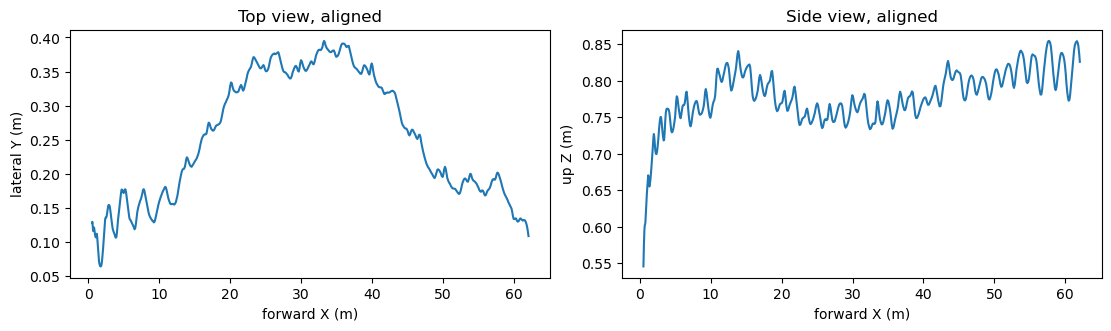

In [5]:
t = SP.clean_for_angles(RUNNER)
aligned = t["raw64"]                                  # (frames, 64, 3) in the shared frame
print(f"kept frames {t['start']}-{t['start'] + t['n_frames'] - 1} of {t['n_raw']} "
      f"| step-5 correction {t['tilt_deg']:+.2f} deg")

p = aligned[:, SP.MK_PELVIS_ALL].mean(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
ax[0].plot(p[:, 0], p[:, 1])
ax[0].set(title="Top view, aligned", xlabel="forward X (m)", ylabel="lateral Y (m)")
ax[1].plot(p[:, 0], p[:, 2])
ax[1].set(title="Side view, aligned", xlabel="forward X (m)", ylabel="up Z (m)");

## 4 · Self-checks (fail loudly if the alignment ever breaks)

In [6]:
# 1. Forward is +X: the pelvis ends ~60 m ahead and never drifts a metre sideways.
assert p[-1, 0] > 55 and np.abs(p[:, 1]).max() < 1.0
# 2. Gravity is untouched: aligned Z = raw Z minus one constant (the origin shift).
kept = raw[t["start"]:t["start"] + t["n_frames"], :, 2]
assert np.ptp(kept - aligned[:, :, 2]) < 1e-9
# 3. Origin: the rear heel sits at (0, 0, 0) in the set position.
rear = SP.MK_R_HEEL if aligned[0, SP.MK_R_HEEL, 0] <= aligned[0, SP.MK_L_HEEL, 0] else SP.MK_L_HEEL
assert np.allclose(aligned[0, rear], 0)
print("globalization checks passed")

globalization checks passed
